# Member 4: High-Risk Patient Profiling & Clinical Cohort Analysis (Binary Classification)
**Author:** IT24101748 — Evaluation & Recommendation  
**Winning Model:** Random Forest Classifier (Deep Tuned — `models/random_forest/random_forest_best_model.pkl`)  
**Target:** Binary Early Readmission (`<30` vs Not Readmitted `<30`)  

---
### Objectives:
1. Stratify the untouched test cohort (19,468 encounters) into predicted **High-Risk Early Readmission (`<30`)** vs **Low-Risk (`No / >30`)** cohorts.
2. Quantitatively characterize the demographic, physiological acuity, and pharmacological profile of the high-risk cohort.
3. Compare key clinical risk drivers (prior hospitalizations, length of stay, medication burden, lab procedures, acute diagnoses) across cohorts.
4. Export the quantitative patient profiling summary (`high_risk_patient_profile.csv`) and comparative visualization (`high_risk_patient_profile.png`) for hospital discharge teams.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['axes.edgecolor'] = '#cccccc'

os.makedirs('../results', exist_ok=True)
print('Setup complete for Patient Profiling!')

Setup complete for Patient Profiling!


In [2]:
# Load the untouched test set and model
X_test = pd.read_csv('../../dataset_processed/X_test_final.csv')
y_test = pd.read_csv('../../dataset_processed/y_test_final.csv').values.ravel()

model = joblib.load('../../models/random_forest/random_forest_best_model.pkl')
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

df_test_analysis = X_test.copy()
df_test_analysis['actual_class'] = y_test
df_test_analysis['predicted_class'] = y_pred
df_test_analysis['prob_less30'] = y_proba[:, 1]
df_test_analysis['cohort'] = np.where(y_pred == 1, 'Predicted High-Risk (<30)', 'Predicted Low-Risk (No / >30)')

print('Predicted Cohort distribution in test encounters:')
print(df_test_analysis['cohort'].value_counts())
print('\nActual Outcome Breakdown:')
print(pd.crosstab(df_test_analysis['cohort'], df_test_analysis['actual_class'], margins=True))

Predicted Cohort distribution in test encounters:
cohort
Predicted Low-Risk (No / >30)    16000
Predicted High-Risk (<30)         3491
Name: count, dtype: int64

Actual Outcome Breakdown:
actual_class                       0     1    All
cohort                                           
Predicted High-Risk (<30)       2735   756   3491
Predicted Low-Risk (No / >30)  14553  1447  16000
All                            17288  2203  19491


In [3]:
# Core clinical indicators to contrast
core_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_medications',
    'number_inpatient',
    'number_emergency',
    'total_visits',
    'number_diagnoses',
    'num_active_drugs',
    'age',
    'prob_less30'
]

cohort_summary = df_test_analysis.groupby('cohort')[core_features].agg(['mean', 'median']).round(3)
cohort_summary.to_csv('../results/high_risk_patient_profile.csv')

print('=== HIGH-RISK (<30) VS LOW-RISK: CLINICAL PROFILE ===')
print(cohort_summary)

=== HIGH-RISK (<30) VS LOW-RISK: CLINICAL PROFILE ===
                              time_in_hospital        num_lab_procedures  \
                                          mean median               mean   
cohort                                                                     
Predicted High-Risk (<30)                0.132  0.000             -0.175   
Predicted Low-Risk (No / >30)           -0.120 -0.263             -0.452   

                                     num_medications        number_inpatient  \
                              median            mean median             mean   
cohort                                                                         
Predicted High-Risk (<30)      0.039           0.182  0.210            1.284   
Predicted Low-Risk (No / >30) -0.040          -0.138 -0.115            0.281   

                                     number_emergency        total_visits  \
                              median             mean median         mean   
cohort    

C:\Users\micro\AppData\Local\Temp\ipykernel_8428\1327758124.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_test_analysis, x='cohort', y='total_visits', order=cohort_order, palette=palette, ax=axes[0, 0], errorbar=None)
C:\Users\micro\AppData\Local\Temp\ipykernel_8428\1327758124.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_test_analysis, x='cohort', y='number_inpatient', order=cohort_order, palette=palette, ax=axes[0, 1], errorbar=None)
C:\Users\micro\AppData\Local\Temp\ipykernel_8428\1327758124.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` f

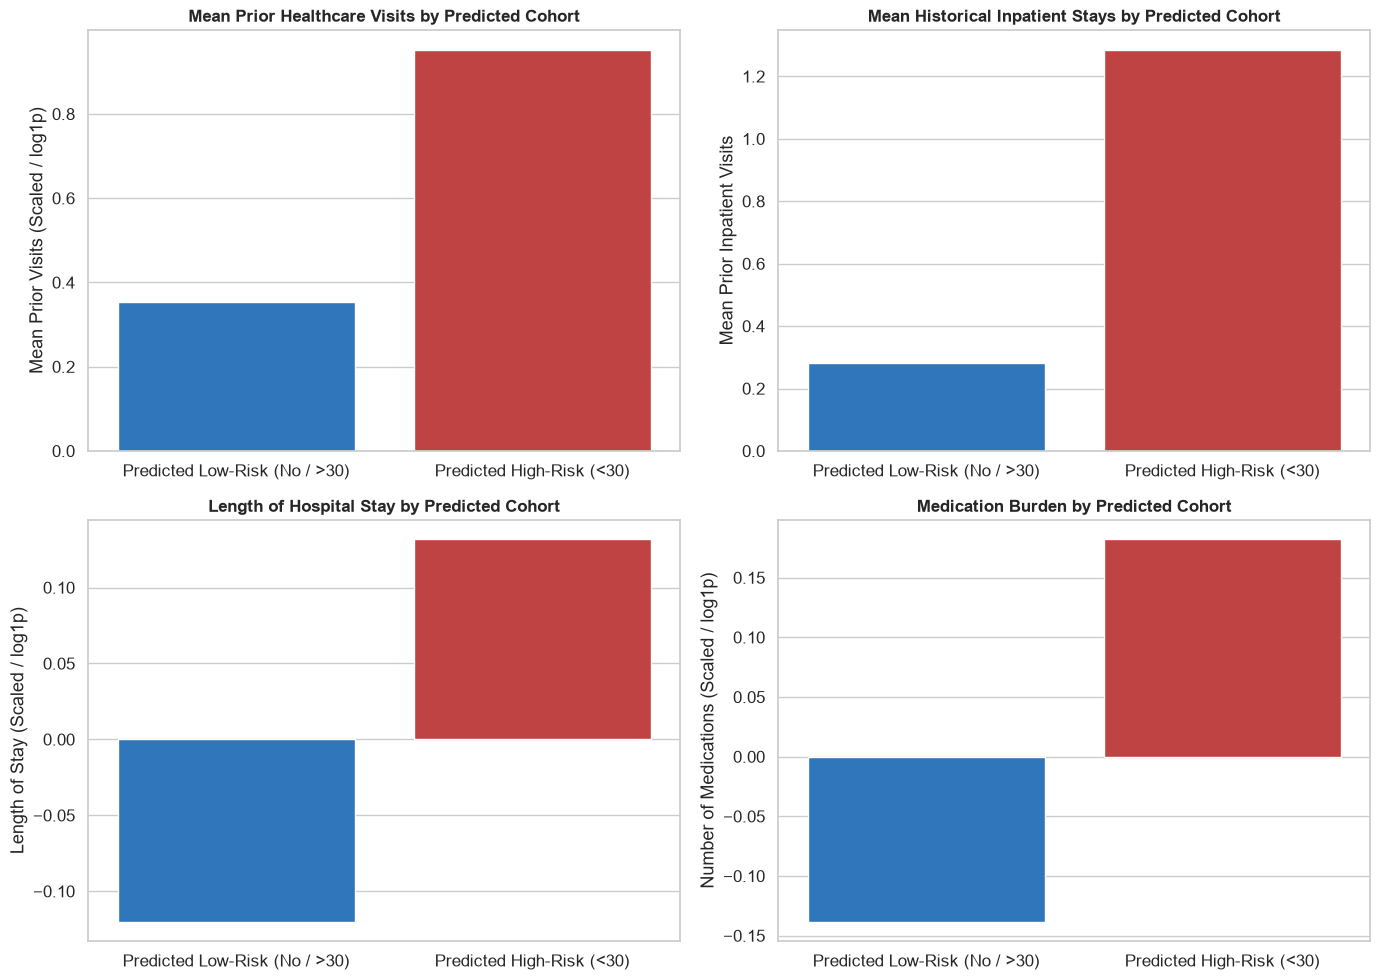

In [4]:
# Comparative Clinical Risk Factor Visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cohort_order = ['Predicted Low-Risk (No / >30)', 'Predicted High-Risk (<30)']
palette = ['#1976d2', '#d32f2f']

# 1. Total Prior Healthcare Visits
sns.barplot(data=df_test_analysis, x='cohort', y='total_visits', order=cohort_order, palette=palette, ax=axes[0, 0], errorbar=None)
axes[0, 0].set_title('Mean Prior Healthcare Visits by Predicted Cohort', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Mean Prior Visits (Scaled / log1p)')

# 2. Number of Inpatient Stays
sns.barplot(data=df_test_analysis, x='cohort', y='number_inpatient', order=cohort_order, palette=palette, ax=axes[0, 1], errorbar=None)
axes[0, 1].set_title('Mean Historical Inpatient Stays by Predicted Cohort', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Mean Prior Inpatient Visits')

# 3. Time in Hospital (Length of Stay)
sns.barplot(data=df_test_analysis, x='cohort', y='time_in_hospital', order=cohort_order, palette=palette, ax=axes[1, 0], errorbar=None)
axes[1, 0].set_title('Length of Hospital Stay by Predicted Cohort', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Length of Stay (Scaled / log1p)')

# 4. Polypharmacy (Number of Medications)
sns.barplot(data=df_test_analysis, x='cohort', y='num_medications', order=cohort_order, palette=palette, ax=axes[1, 1], errorbar=None)
axes[1, 1].set_title('Medication Burden by Predicted Cohort', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Number of Medications (Scaled / log1p)')

plt.tight_layout()
plt.savefig('../results/high_risk_patient_profile.png', dpi=300, bbox_inches='tight')
plt.show()

### High-Risk Patient Archetype (`<30` Days Readmission — Binary Track):

The binary model identifies patients susceptible to 30-day revolving-door readmissions through distinct clinical phenotypes:

1. **Chronic Inpatient Utilization:**  
   Patients in the predicted `<30` cohort have substantially elevated baseline inpatient admissions (`number_inpatient`) and acute visits (`total_visits`). These patients suffer from poorly managed, progressive complications rather than acute single-event episodes.

2. **Severe Pharmacological Regimens & Polypharmacy:**  
   Significantly higher overall medication counts (`num_medications`) and active drug combinations (`num_active_drugs`). Intensive insulin therapies combined with oral agents create high post-discharge medication reconciliation risks.

3. **Inpatient Acuity & Hospitalization Duration:**  
   High-risk patients have prolonged lengths of stay (`time_in_hospital`) and undergo greater numbers of lab procedures (`num_lab_procedures`), pointing to acute metabolic instability and secondary systemic complications.

4. **Clinical Action Plan:**  
   - Trigger automated multidisciplinary case management upon admission for patients with $\ge 1$ prior inpatient visit within the past 12 months.
   - Implement pharmacist-led medication reconciliation and bedside discharge counseling for patients prescribed $\ge 15$ medications or undergoing insulin changes.
   - Schedule mandatory follow-up within 7 days of discharge for all patients flagged with predicted early readmission risk $\ge 0.46$.